# Noise and fidelity

Each physical gate is followed by a composite channel, $\mathcal{E}=\mathcal{D}_p\circ\mathcal{R}\circ\mathcal{V}$:
coherent error, then relaxation during the gate, then depolarising noise. The depolarising strength $p$ is solved so
that every gate reproduces its published fidelity exactly. Read-out error and idle relaxation are added on top.

QPUTwin at http://localhost:8000: ready, 7 twins reachable


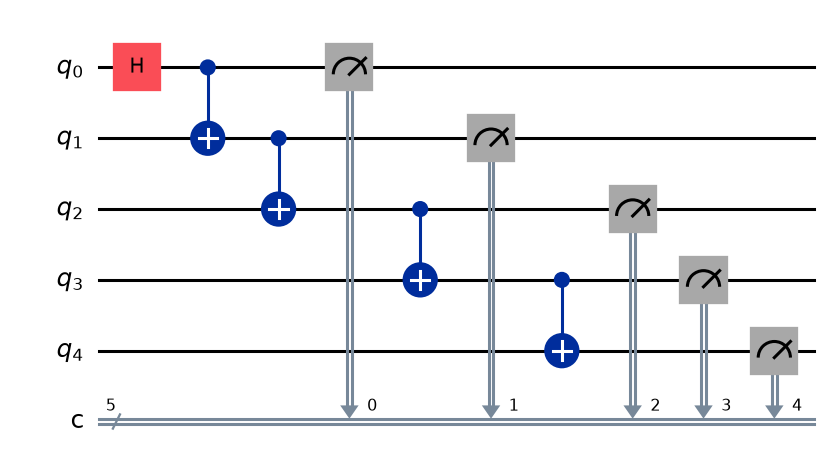

In [1]:
from qputwin_demo import *

connect()
circuit = ghz(5)
draw(circuit)

## Ideal against noisy

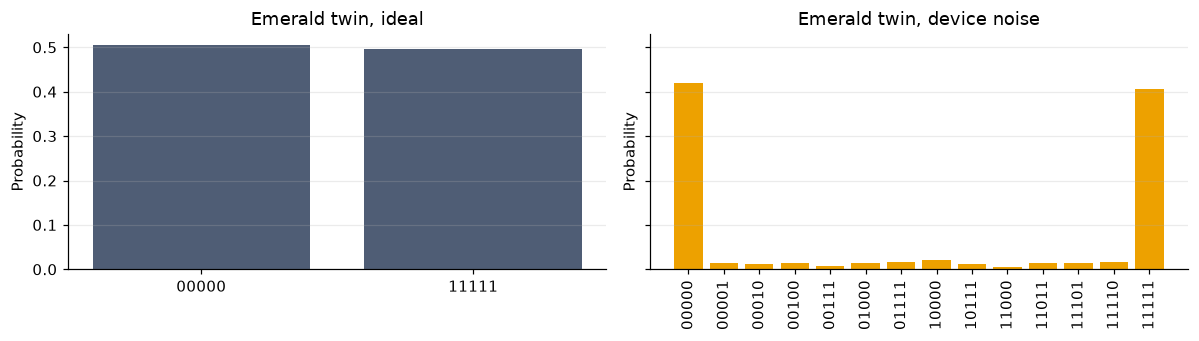

In [2]:
ideal = run("iqm_emerald", circuit, shots=4096)
noisy = run("iqm_emerald", circuit, noise=True, shots=4096)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
plot_counts(ideal["result"]["counts"], "Emerald twin, ideal", ax=axes[0], color="#4F5D75")
plot_counts(noisy["result"]["counts"], "Emerald twin, device noise", ax=axes[1], color=COLORS["iqm_emerald"], top=14)
fig.tight_layout()
plt.show()

## The noise report

The job reports each gate's channel. `depolarizing_p` is the solved value. A gate is `budget_limited` when relaxation
alone already reaches the published error, so $p$ is set to zero and the case is reported rather than hidden.

In [3]:
report = noisy["result"]["noise"]
print("Engine:", report["engine"], "| Purity:", round(report["purity"], 4), "| Trace:", round(report["trace"], 10))
print("Estimated success probability:", round(report["estimated_success_probability"], 4))
pd.DataFrame(report["per_gate"]).T[["count", "fidelity", "depolarizing_p", "budget_limited"]]

Engine: density_matrix | Purity: 0.8543 | Trace: 1.0
Estimated success probability: 0.8364


,count,fidelity,depolarizing_p,budget_limited
cz,4,0.995,0.002248,False
prx,9,0.9993,0.0,True


## Executing beats estimating

The usual shortcut multiplies gate and read-out fidelities. QPUTwin reports both that estimate and the exact result, so
the gap is visible. The estimate misses idle decoherence, which is why it flatters the superconducting twins.

These jobs set `routing=True`. A GHZ chain embeds in a lattice, but numbering qubits straight along it would run off the
end of a row, and the twin would reject that. The router finds a path through the lattice with no SWAPs.

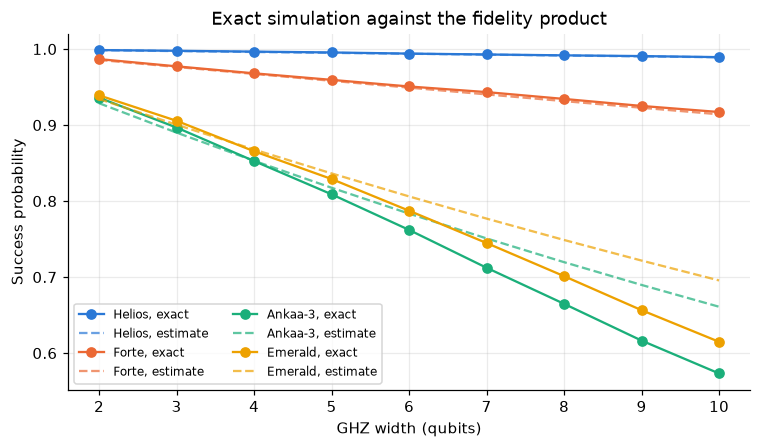

,exact,estimate
twin,,
Helios,0.989,0.989
Forte,0.917,0.914
Ankaa-3,0.573,0.661
Emerald,0.615,0.696


In [4]:
widths = range(2, 11)
rows = []
for backend in BACKENDS:
    for n in widths:
        r = run(backend, ghz(n), noise=True, routing=True, shots=20_000)
        rows.append({"twin": backend, "n": n, "exact": success(r, ["0" * n, "1" * n]),
                     "estimate": r["result"]["noise"]["estimated_success_probability"]})
sweep = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 4.2))
for backend, group in sweep.groupby("twin", sort=False):
    ax.plot(group.n, group.exact, "o-", color=COLORS[backend], label=f"{NAMES[backend]}, exact")
    ax.plot(group.n, group.estimate, "--", color=COLORS[backend], alpha=0.7, label=f"{NAMES[backend]}, estimate")
ax.set(xlabel="GHZ width (qubits)", ylabel="Success probability", title="Exact simulation against the fidelity product")
ax.legend(ncols=2, fontsize=8)
plt.show()

sweep[sweep.n == 10].assign(twin=lambda f: f.twin.map(NAMES)).set_index("twin")[["exact", "estimate"]].round(3)

## Error budget

Each noise term can be switched on alone, which separates what costs the fidelity on each device. Relaxation and idle
are measured together, because idle noise is relaxation during the windows a qubit waits.

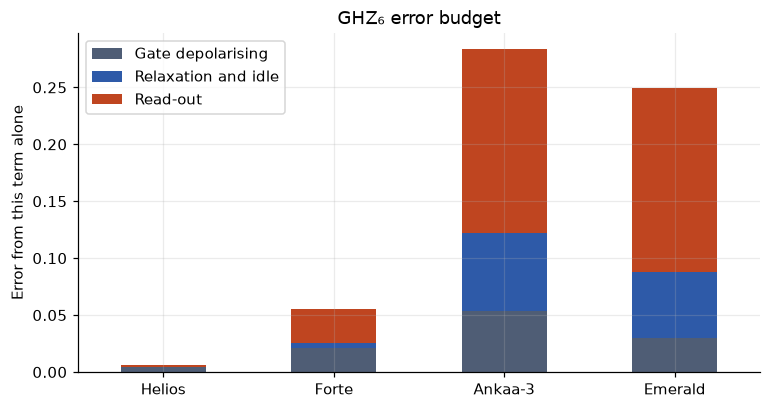

,Gate depolarising,Relaxation and idle,Read-out
Helios,0.0042,0.0000,0.0021
Forte,0.0210,0.0041,0.0301
Ankaa-3,0.0539,0.0678,0.1617
Emerald,0.0303,0.0572,0.1617


In [5]:
TERMS = ["depolarizing", "relaxation", "idle", "readout", "coherent", "crosstalk", "reset_errors",
         "correlated_readout", "leakage", "quasi_static"]

def only(*terms):
    return {"model": "device", **dict.fromkeys(TERMS, False), **dict.fromkeys(terms, True)}

circuit = ghz(6)
good = ["0" * 6, "1" * 6]
groups = {"Gate depolarising": ["depolarizing"], "Relaxation and idle": ["relaxation", "idle"], "Read-out": ["readout"]}
budget = {NAMES[b]: {name: 1 - success(run(b, circuit, noise=only(*terms), shots=50_000, engine="density_matrix"), good)
                     for name, terms in groups.items()} for b in BACKENDS}
budget = pd.DataFrame(budget).T

budget.plot.bar(stacked=True, figsize=(8, 4), color=["#4F5D75", "#2E5AA8", "#BF4520"])
plt.ylabel("Error from this term alone")
plt.title("GHZ₆ error budget")
plt.xticks(rotation=0)
plt.show()
budget.round(4)

## How sensitive is each device?

`scale` multiplies every error rate. Improving a superconducting device moves the result much more than the same
relative improvement on a trapped-ion device.

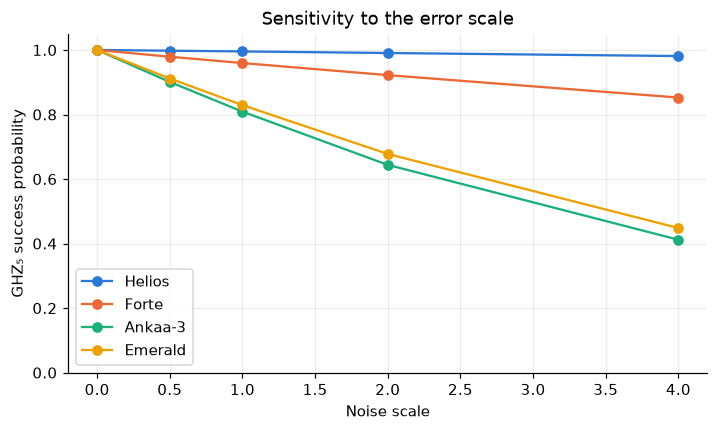

In [6]:
scales = [0, 0.5, 1, 2, 4]
circuit = ghz(5)
fig, ax = plt.subplots(figsize=(7.5, 4))
for backend in BACKENDS:
    values = [success(run(backend, circuit, noise={"model": "device", "scale": s}, shots=20_000), ["00000", "11111"])
              for s in scales]
    ax.plot(scales, values, "o-", color=COLORS[backend], label=NAMES[backend])
ax.set(xlabel="Noise scale", ylabel="GHZ₅ success probability", title="Sensitivity to the error scale", ylim=(0, 1.05))
ax.legend()
plt.show()

## Density matrices

For small circuits the job can return the final density matrix. Noise appears as reduced coherences, and as population
outside $|00\rangle$ and $|11\rangle$.

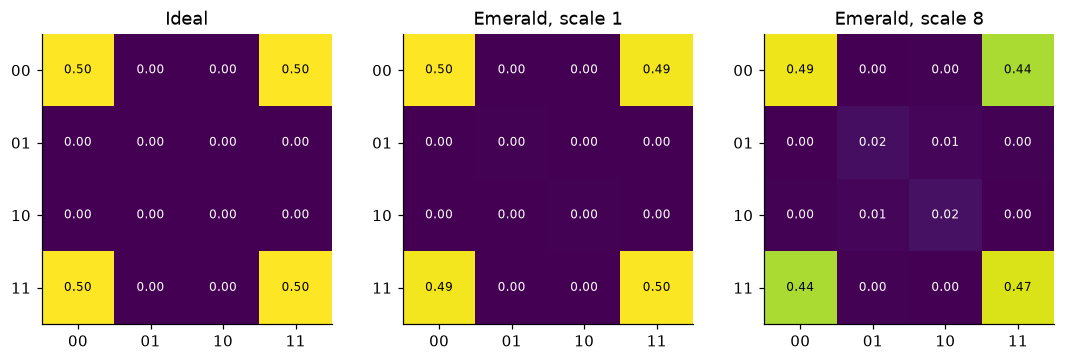

In [7]:
def rho(backend, scale):
    r = run(backend, bell(), noise={"model": "device", "scale": scale, "readout": False}, return_density_matrix=True, shots=64)
    return np.abs(np.array(r["result"]["density_matrix"])[..., 0] + 1j * np.array(r["result"]["density_matrix"])[..., 1])

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, (title, matrix) in zip(axes, [("Ideal", rho("iqm_emerald", 0)), ("Emerald, scale 1", rho("iqm_emerald", 1)),
                                      ("Emerald, scale 8", rho("iqm_emerald", 8))]):
    image = ax.imshow(matrix, vmin=0, vmax=0.5, cmap="viridis")
    ax.set(title=title, xticks=range(4), yticks=range(4), xticklabels=["00", "01", "10", "11"], yticklabels=["00", "01", "10", "11"])
    ax.grid(False)
    for (i, j), value in np.ndenumerate(matrix):
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", color="white" if value < 0.3 else "black", fontsize=8)
fig.tight_layout()
plt.show()

## Two noisy engines agree

The density matrix is exact, but its memory grows as $4^n$. Monte-Carlo trajectories cost one statevector each, so they
reach wider circuits. Their error should fall roughly as $T^{-1/2}$ with the number of trajectories $T$, until it meets
the sampling noise of the 20,000 shots used to compare them. No engine can measure below that floor.

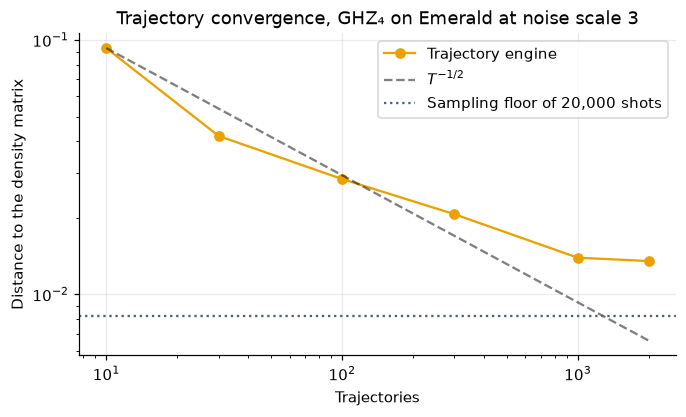

In [8]:
circuit = ghz(4)
noise = {"model": "device", "scale": 3, "leakage": False, "quasi_static": False}
exact = run("iqm_emerald", circuit, noise=noise, engine="density_matrix", shots=200_000)["result"]["counts"]

def distance(p, q):
    total_p, total_q = sum(p.values()), sum(q.values())
    return 0.5 * sum(abs(p.get(k, 0) / total_p - q.get(k, 0) / total_q) for k in set(p) | set(q))

counts = [10, 30, 100, 300, 1000, 2000]
errors = [np.mean([distance(exact, run("iqm_emerald", circuit, noise={**noise, "trajectories": t}, engine="trajectory",
                                       shots=20_000, seed=s)["result"]["counts"]) for s in range(4)]) for t in counts]

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.loglog(counts, errors, "o-", color=COLORS["iqm_emerald"], label="Trajectory engine")
ax.loglog(counts, errors[0] * np.sqrt(counts[0] / np.array(counts)), "k--", alpha=0.5, label="$T^{-1/2}$")
floor = np.mean([distance(exact, run("iqm_emerald", circuit, noise=noise, engine="density_matrix", shots=20_000, seed=s)["result"]["counts"])
                 for s in range(1, 5)])
ax.axhline(floor, color="#4F5D75", linestyle=":", label="Sampling floor of 20,000 shots")
ax.set(xlabel="Trajectories", ylabel="Distance to the density matrix", title="Trajectory convergence, GHZ₄ on Emerald at noise scale 3")
ax.legend()
plt.show()